## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anh Bach

**Date:** 10/19/2026

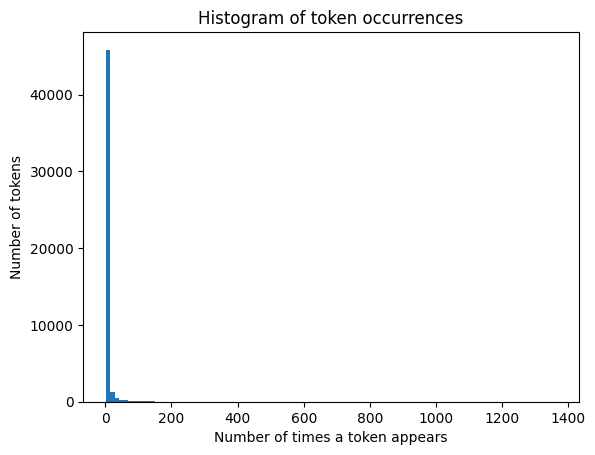

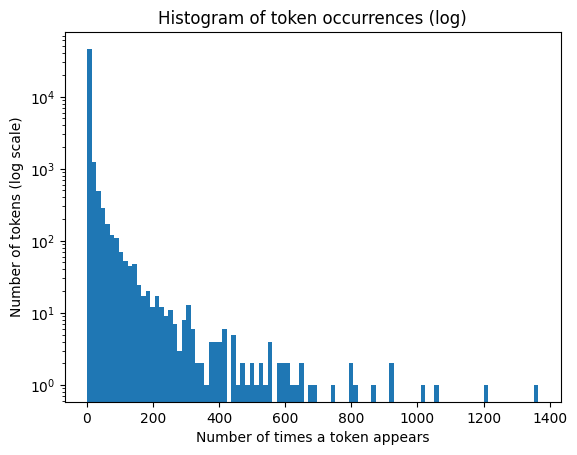

In [2]:
#Q1 Answers
import matplotlib.pyplot as plt

counts = []
for token, count in token_freq:
    counts.append(count)

plt.hist(counts, bins=100)
plt.xlabel("Number of times a token appears")
plt.ylabel("Number of tokens")
plt.title("Histogram of token occurrences")
plt.show()

plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Number of times a token appears")
plt.ylabel("Number of tokens (log scale)")
plt.title("Histogram of token occurrences (log)")
plt.show()


Q1 Explanation: The histogram is very right-skewed. Almost all tokens are in the first bar near zero, so most tokens are rare. A small number of tokens show up hundreds of times or more, which makes a long tail to the right. On the log scale, the number of tokens keeps dropping as the count goes up.

In [3]:
#Q2-1 Answers
import pandas as pd
from sklearn.model_selection import train_test_split

df_phish = pd.read_parquet("data/Phishing_clean.parquet")

y = df_phish["Email Type"]
X = df_phish.drop(columns="Email Type")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (14907, 2711)
Test: (3727, 2711)


In [4]:
#Q2-2 Answers
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)

print("Train R^2:", round(reg.score(X_train, y_train), 3))
print("Test R^2:", round(reg.score(X_test, y_test), 3))

Train R^2: 0.766
Test R^2: 0.67


Q2-2 Explanation: The R^2 is 0.766 on the training set and 0.67 on the test set. The model does a bit worse on the test set, so it might be overfitting a little. This makes sense since there are 2,711 features in the model.

In [5]:
#Q2-3 Answers
coefs = pd.DataFrame({"word": X.columns, "coef": reg.coef_})
coefs["abs_coef"] = coefs["coef"].abs()

coefs.sort_values("abs_coef", ascending=False).head(10)

,word,coef,abs_coef
1504,background-image:,-1.201203,1.201203
740,localized,0.815112,0.815112
906,aging,0.735023,0.735023
2362,thermal,0.590412,0.590412
1406,"helvetica,",0.587472,0.587472
835,intervention,-0.580474,0.580474
1302,erectile,0.575784,0.575784
1511,burning,-0.569225,0.569225
1839,form.,0.560255,0.560255
2559,april's,-0.525984,0.525984


Q2-3 Explanation: The words with the largest coefficients in absolute value are "background-image:", "localized", "aging", "thermal", "helvetica,", "intervention" and "erectile". Words with positive coefficients like "aging" and "erectile" push the prediction toward scam. Words with negative coefficients like "background-image:" and "intervention" push it toward not scam. Some of the top tokens are formatting words, so the way an email is formatted could also affect the predictions.

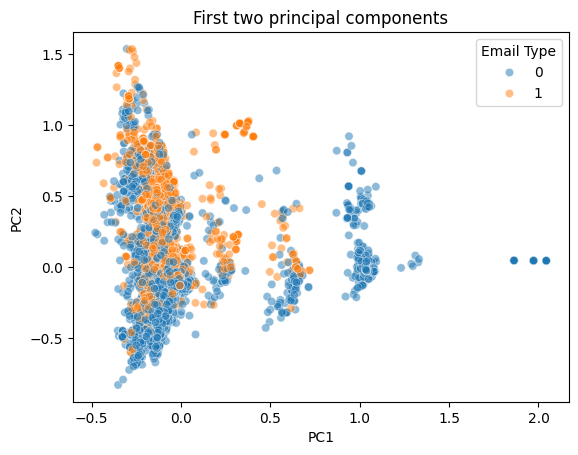

Variance retained: [0.0111 0.0086]


In [6]:
#Q3 Answers
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_phish = PCA(n_components=2).fit(X)
X_pca = pca_phish.transform(X)

df_pca = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Email Type": y})

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Email Type", alpha=0.5)
plt.title("First two principal components")
plt.show()

print("Variance retained:", pca_phish.explained_variance_ratio_.round(4))

Q3 Explanation: Most phishing and non-phishing emails overlap in one big cluster on the left side of the plot, so the first two components do not separate them well. Phishing emails tend to be a bit higher on PC2. The smaller clusters on the right side around PC1 = 0.6, 1.0 and 2.0 are almost all non-phishing emails. The two components only keep about 2 percent of the total variance, so a lot of information could be lost.

In [7]:
#Q4 Answers

pca_2610 = PCA(n_components=2610).fit(X_train)

X_train_pca = pca_2610.transform(X_train)
X_test_pca = pca_2610.transform(X_test)

reg_pca = LinearRegression().fit(X_train_pca, y_train)

print("Train R^2:", round(reg_pca.score(X_train_pca, y_train), 3))
print("Test R^2:", round(reg_pca.score(X_test_pca, y_test), 3))
print("Variance retained:", round(100 * pca_2610.explained_variance_ratio_.sum(), 2), "%")

Train R^2: 0.765
Test R^2: 0.672
Variance retained: 99.98 %


Q4 Explanation: The R^2 is 0.765 on the training set and 0.672 on the test set. This is almost the same as the original regression, which had 0.766 on the training set and 0.67 on the test set. The 2,610 components keep 99.98 percent of the variance, so the performance barely changes.

Q5 Answers: The original data has 2,711 word columns, and many of them overlap since some words tend to show up together in the same emails. This can make the regression coefficients unstable and lead to overfitting. The principal components do not have this problem because they are uncorrelated with each other. They are also ordered by how much variance they keep, so we can drop the last ones since they have very little information. Here, the 2,610 components kept 99.98 percent of the variance while using about 100 fewer features. The test R^2 was about the same as the original regression, so the components could give a simpler model that still predicts about as well.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [cf7a026fd61a4d956a96b6d6029195d4c935c142]
- **AI tool and model used:** [GPT-6]

### *Prompts used

1. [attached notebook] here is my notebook. highlight the parts that i made a mistake in or should change to better answer questions
2. should i change anything in my code or anything else

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1.  **Q1 – Minor wording improvement:** Replace "first bar near zero" with "most tokens have very low occurrence counts," since token frequencies start at 1, not 0.

2. **Q2 – Clarify overfitting:** The difference between training R² (0.766) and test R² (0.670) suggests some overfitting. Also clarify that large coefficients indicate associations with predictions, not causal effects.

3. **Q3 – Improve interpretation:** The first two components explain only about 2% of the total variance. However, this does not necessarily mean 98% of the information useful for predicting phishing is lost.

4. **Q4 – Expand comparison:** PCA reduces the number of features from 2,711 to 2,610, while test R² increases only from 0.670 to 0.672. This difference is too small to conclude that PCA meaningfully improves prediction.

5. **Q5 – Correct misleading statement:** Saying that low-variance components contain "very little information" is inaccurate. They explain less variation in X but may still contain useful information for predicting y. PCA can reduce multicollinearity but does not automatically prevent overfitting.

Overall: No major coding errors were identified. The main improvements concern statistical interpretation, especially in Q3 and Q5.

2. Your code is correct for all five questions, so I wouldn't make any major changes. After checking your notebook again, I recommend only these adjustments:

1. Q2 – Explanation: You list only 7 of the 10 largest coefficients. Consider adding burning, form., and april's for completeness.

2. Q3 – Explanation: Replace "a lot of information could be lost" with "the two components capture only about 2% of the total variance, so they may not represent all the patterns in the dataset."

3. Q4 – Explanation: Mention that PCA removes only 101 of the 2,711 features and improves test R² by just 0.002, which is not a meaningful improvement on its own.

4. Q5 – Explanation: Clarify that PCA reduces multicollinearity but does not automatically prevent overfitting. Low-variance components can still contain useful predictive information.

5. Code – File paths: Make sure data/all_tokens.pickle and data/Phishing_clean.parquet point to the correct files when submitting.

I don't see any additional coding mistakes likely to cost you points.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1. Improve wording and interpretations in Q1–Q5 | Accept  | The suggestions make my explanations clearer and more accurate. The suggested changes are consistent with my original plots, R^2 values, and PCA results. |
| 2. Add missing Q2 coefficients, clarify Q3–Q5 explanations, and check file paths | Modify | Some suggestions overlap with the first prompt. I will add the missing details and improve the explanations, but keep the code unchanged since ChatGPT did not point out any errors. THe file paths look correct so I will not need to change anything there. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

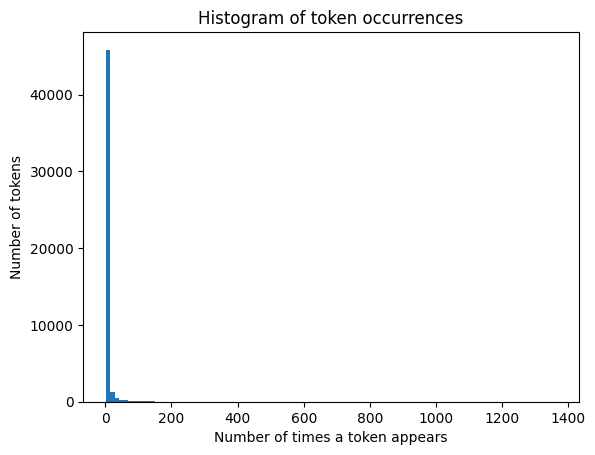

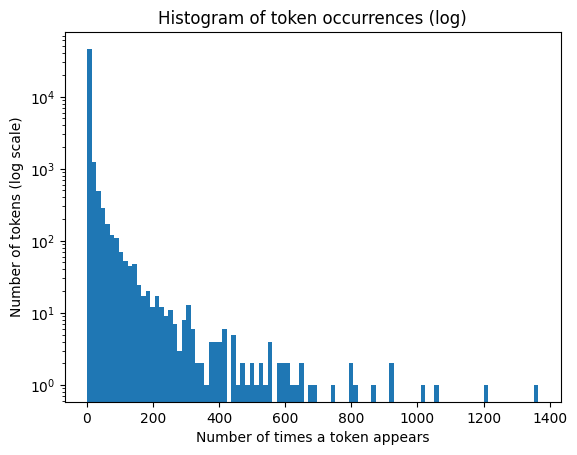

In [8]:
# Your Phase 2 solution to the problem goes here.

#Q1 Answers
import matplotlib.pyplot as plt

counts = []
for token, count in token_freq:
    counts.append(count)

plt.hist(counts, bins=100)
plt.xlabel("Number of times a token appears")
plt.ylabel("Number of tokens")
plt.title("Histogram of token occurrences")
plt.show()

plt.hist(counts, bins=100)
plt.yscale("log")
plt.xlabel("Number of times a token appears")
plt.ylabel("Number of tokens (log scale)")
plt.title("Histogram of token occurrences (log)")
plt.show()


Q1 Explanation: The histogram is very right-skewed. Most tokens have very low occurrence counts, so most tokens are rare. A small number of tokens show up hundreds of times or more, which makes a long tail to the right. On the log scale, the number of tokens keeps dropping as the count goes up.

In [9]:
#Q2-1 Answers
import pandas as pd
from sklearn.model_selection import train_test_split

df_phish = pd.read_parquet("data/Phishing_clean.parquet")

y = df_phish["Email Type"]
X = df_phish.drop(columns="Email Type")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=125)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (14907, 2711)
Test: (3727, 2711)


In [10]:
#Q2-2 Answers
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(X_train, y_train)

print("Train R^2:", round(reg.score(X_train, y_train), 3))
print("Test R^2:", round(reg.score(X_test, y_test), 3))

Train R^2: 0.766
Test R^2: 0.67


Q2-2 Explanation: The R^2 is 0.766 on the training set and 0.67 on the test set. The model does worse on the test set, which suggests some overfitting. This makes sense since there are 2,711 features in the model.

In [11]:
#Q2-3 Answers
coefs = pd.DataFrame({"word": X.columns, "coef": reg.coef_})
coefs["abs_coef"] = coefs["coef"].abs()

coefs.sort_values("abs_coef", ascending=False).head(10)

,word,coef,abs_coef
1504,background-image:,-1.201203,1.201203
740,localized,0.815112,0.815112
906,aging,0.735023,0.735023
2362,thermal,0.590412,0.590412
1406,"helvetica,",0.587472,0.587472
835,intervention,-0.580474,0.580474
1302,erectile,0.575784,0.575784
1511,burning,-0.569225,0.569225
1839,form.,0.560255,0.560255
2559,april's,-0.525984,0.525984


Q2-3 Explanation: The words with the largest coefficients in absolute value are "background-image:", "localized", "aging", "thermal", "helvetica,", "intervention", "erectile", "burning", "form.", and "april's". Words with positive coefficients like "aging" and "erectile" push the prediction toward scam. Words with negative coefficients like "background-image:" and "intervention" push it toward not scam. Some of the top tokens are formatting words, so the way an email is formatted could also affect the predictions.

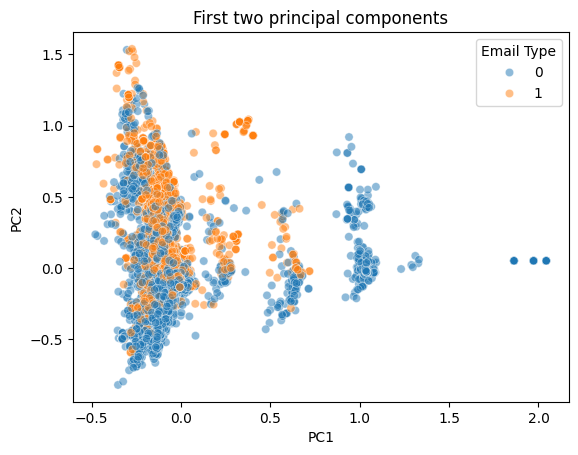

Variance retained: [0.0111 0.0086]


In [12]:
#Q3 Answers
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

pca_phish = PCA(n_components=2).fit(X)
X_pca = pca_phish.transform(X)

df_pca = pd.DataFrame({"PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "Email Type": y})

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Email Type", alpha=0.5)
plt.title("First two principal components")
plt.show()

print("Variance retained:", pca_phish.explained_variance_ratio_.round(4))

Q3 Explanation: Most phishing and non-phishing emails overlap in one big cluster on the left side of the plot, so the first two components do not separate them well. Phishing emails tend to be a bit higher on PC2. The smaller clusters on the right side around PC1 = 0.6, 1.0 and 2.0 are almost all non-phishing emails. The two components only keep about 2 percent of the total variance, so they may not capture all the patterns in the data. However, this does not mean most of the information useful for predicting phishing is lost.

In [13]:
#Q4 Answers

pca_2610 = PCA(n_components=2610).fit(X_train)

X_train_pca = pca_2610.transform(X_train)
X_test_pca = pca_2610.transform(X_test)

reg_pca = LinearRegression().fit(X_train_pca, y_train)

print("Train R^2:", round(reg_pca.score(X_train_pca, y_train), 3))
print("Test R^2:", round(reg_pca.score(X_test_pca, y_test), 3))
print("Variance retained:", round(100 * pca_2610.explained_variance_ratio_.sum(), 2), "%")

Train R^2: 0.765
Test R^2: 0.672
Variance retained: 99.98 %


Q4 Explanation: The R^2 is 0.765 on the training set and 0.672 on the test set. This is almost the same as the original regression, which had 0.766 on the training set and 0.67 on the test set. The 2,610 components keep 99.98 percent of the variance while removing 101 of the original 2,711 features. The performance barely changes, and the 0.002 improvement in test R^2 is too small to say that PCA meaningfully improves predictions.

The original data has 2,711 word columns, and many of them overlap since some words tend to show up together in the same emails. This can make the regression coefficients unstable and potentially contribute to overfitting. Principal components help with this issue because they are uncorrelated with each other, although PCA does not automatically prevent overfitting. They are also ordered by how much variance they keep, so we can drop the last ones since they explain less variance, although they may still contain useful information for prediction. Here, the 2,610 components kept 99.98 percent of the variance while using about 100 fewer features. The test R^2 was about the same as the original regression, so the components could give a simpler model that still predicts about as well.

### *Reflection on AI assistance
In your own words without generative AI.

ChatGPT helped me improve my explanations for Q1 through Q5 without making major changes to my code. Most of the changes were about making my interpretations clearer. For Q2, I explained the overfitting more clearly and added the missing coefficients. For Q3, I clarified that the first two components explain about 2% of the variance, but this does not necessarily mean most of the useful information for prediction is lost. For Q4 and Q5, I improved my explanations of PCA and its performance. A limitation I saw was that Chat mostly suggested wording changes rather than finding coding mistakes. Some suggestions were also repeated between the two prompts. It also did not rerun the full analysis, so I could not completely rely on its results. As such, to verify the suggestions, I compared them with my original code, plots, and R^2 values. My remaining concerns are that the original regression shows some overfitting, the first two components do not separate the email types that well, and unexpectedly, PCA only slightly improves the test R^2.